# Proyecto de 1er Bimestre: Sistema de Recuperación de Información (SRI) — Corpus FiQA-2018 (v2)
**Asignatura:** Recuperación de Información — Prof. Iván Carrera  
**Fecha de entrega:** 23 de noviembre de 2026  
**Corpus:** `BeIR/fiqa` (FiQA-2018 — *Financial Opinion Mining and Question Answering*, 57,638 documentos financieros, consultas de prueba y juicios de relevancia `qrels`).  
**Fuente oficial:** `https://huggingface.co/datasets/BeIR/fiqa`

Este notebook reúne **todo el sistema en un único archivo `.ipynb`** y cubre cada parámetro exigido en el documento del proyecto:

| Requerimiento del PDF | Implementación en este notebook |
| :--- | :--- |
| **a. Construcción del índice** | Lectura del corpus (`corpus-00000-of-00001.parquet`), estadísticas exploratorias, normalización, tokenización con NLTK (`RegexpTokenizer`), remoción de *stopwords* e `IndiceInvertido` propio (`df` y `{doc_id: tf}`). |
| **b. Modelo de recuperación** | Implementación propia de **Jaccard (vectores binarios)**, **TF-IDF (similitud de coseno)** con matriz dispersa CSR propia y **Okapi BM25** con soporte de consultas libres y ranking. |
| **c. Recuperación semántica** | Embeddings densos con `sentence-transformers` (`all-MiniLM-L6-v2`) indexados en **FAISS** (`IndexFlatIP` + normalización L2) con validación de integridad en caché. |
| **d. Interfaz básica** | Aplicación web en **Gradio** integrada al final del notebook con las 5 funcionalidades mínimas (consulta libre, selector de modelo, Top-N completo, comparación lado a lado y panel de métricas). |
| **e. Evaluación de resultados** | Evaluación sobre consultas de prueba y `qrels` oficiales de FiQA-2018 calculando **Precision@10**, **Recall@10** y **MAP@100** (sin redondeo prematuro) más persistencia y gráficos. |
| **f. Comparación de modelos** | Análisis por tipo de consulta (longitud y términos técnicos/numéricos) y extracción automática de casos reales con texto completo del documento relevante donde Embeddings supera a BM25/TF-IDF y viceversa. |

> **Nota sobre despliegue gratuito (Entregable 1):** `demo.launch(share=True)` permite probar y compartir la interfaz Gradio directamente desde este notebook (en Google Colab dura hasta 72 h mientras la sesión esté activa). Para una **URL pública permanente**, **Hugging Face Spaces (Gradio)** ofrece 16 GB de RAM gratuitos donde el corpus completo (57,638 docs + PyTorch + FAISS) corre sin problemas; en cambio **Render Free (512 MB RAM)** y **Vercel** son insuficientes en memoria para `sentence-transformers` + FAISS con el corpus completo.

## 0. Configuración de Dependencias y Parámetros Globales
Utilizamos únicamente bibliotecas permitidas (`pandas`, `pyarrow`, `numpy`, `scipy`, `nltk`, `scikit-learn`, `sentence-transformers`, `faiss-cpu`, `matplotlib`, `gradio`, `huggingface_hub`).  
La verificación de recursos NLTK comprueba primero si ya existen en disco para evitar descargas innecesarias en ejecuciones sin conexión.

In [1]:
# Descomenta esta línea si ejecutas en Google Colab o te falta alguna librería (ej. gradio):
# !pip install -q pandas pyarrow numpy scipy nltk scikit-learn sentence-transformers faiss-cpu matplotlib gradio huggingface_hub

import os
import re
import json
import math
import time
import hashlib
from collections import defaultdict, Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import csr_matrix
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import RegexpTokenizer

try:
    from IPython.display import display
except ImportError:
    display = print

# Verificación offline-safe de recursos lingüísticos NLTK
for recurso_ruta, recurso_id in [("corpora/stopwords", "stopwords")]:
    try:
        nltk.data.find(recurso_ruta)
    except LookupError:
        nltk.download(recurso_id, quiet=True)

# Configuración centralizada de rutas y parámetros experimentales
RUTA_PARQUET_LOCAL = "corpus-00000-of-00001.parquet"
RUTA_QUERIES_CACHE = "fiqa_queries.parquet"
RUTA_QRELS_CACHE   = "fiqa_qrels_test.parquet"
RUTA_FAISS_INDEX   = "fiqa_faiss.index"
RUTA_FAISS_META    = "fiqa_faiss_meta.json"
RUTA_EVAL_RESUMEN  = "fiqa_eval_resumen.csv"
RUTA_EVAL_DETALLE  = "fiqa_eval_detalle.parquet"

MAX_DOCS = None                  # None = indexar los 57,638 documentos completos de FiQA-2018
MODELO_EMBEDDINGS = "all-MiniLM-L6-v2"
TOP_K_EVAL = 10                  # k para Precision@k y Recall@k
PROFUNDIDAD_AP = 100             # Profundidad de corte R para Average Precision / MAP

print("Entorno y configuración cargados correctamente.")

Entorno y configuración cargados correctamente.


## 1. Carga del Corpus FiQA-2018, Consultas, Qrels y Preprocesamiento Textual
### Requerimiento (a): Lectura del corpus de documentos en texto plano
El archivo local `corpus-00000-of-00001.parquet` almacena los **57,638 documentos en texto plano** de FiQA-2018 con columnas `_id`, `title` y `text`.

**Mejoras clave implementadas en esta versión:**
1. **Carga vectorizada:** reemplazamos `iterrows()` por iteración directa sobre columnas (`zip`), reduciendo la lectura a menos de medio segundo.
2. **Carga resiliente de `queries` y `qrels` sin depender únicamente de `datasets`:**
   - Prioriza caché local (`fiqa_queries.parquet` y `fiqa_qrels_test.parquet`) para ejecuciones rápidas y sin conexión.
   - Si no existe caché local, intenta cargar mediante `datasets` (si está instalado) o directamente vía `huggingface_hub` (`HfApi` + `hf_hub_download`) y guarda la caché local automáticamente.
3. **Auditoría real del corpus:** reportamos documentos vacíos y estadísticas de longitud antes de indexar.

In [2]:
# ============================================================================
# BLOQUE 1A: CARGA DE CORPUS, CONSULTAS Y QRELS CON CACHÉ LOCAL ROBUSTA
# ============================================================================

def cargar_fiqa_corpus(ruta_local=RUTA_PARQUET_LOCAL, max_docs=MAX_DOCS):
    """
    Carga el corpus FiQA-2018 desde Parquet local (o desde Hugging Face si no existe).
    Retorna (corpus_dict, df_stats) donde corpus_dict es {doc_id: texto_completo}.
    """
    if os.path.exists(ruta_local):
        print(f"Cargando corpus desde archivo local: '{ruta_local}'...")
        df_corpus = pd.read_parquet(ruta_local)
    else:
        print("Archivo local no encontrado. Intentando descargar corpus desde Hugging Face...")
        try:
            from datasets import load_dataset
            df_corpus = load_dataset("BeIR/fiqa", "corpus", split="corpus").to_pandas()
        except ImportError:
            df_corpus = _descargar_tabla_hf("BeIR/fiqa", ["corpus"])
        df_corpus.to_parquet(ruta_local, index=False)

    if max_docs is not None:
        df_corpus = df_corpus.head(max_docs)

    corpus_dict = {}
    titulos_no_vacios = 0
    textos_vacios = 0
    longitudes_palabras = []

    ids_col = df_corpus["_id"].tolist()
    titulos_col = df_corpus["title"].tolist() if "title" in df_corpus.columns else [""] * len(df_corpus)
    textos_col = df_corpus["text"].tolist()

    for doc_id, titulo, cuerpo in zip(ids_col, titulos_col, textos_col):
        doc_id_str = str(doc_id)
        t_str = str(titulo).strip() if pd.notna(titulo) else ""
        c_str = str(cuerpo).strip() if pd.notna(cuerpo) else ""
        if t_str:
            titulos_no_vacios += 1
        texto_completo = f"{t_str} {c_str}".strip() if t_str else c_str
        if not texto_completo:
            textos_vacios += 1
        longitudes_palabras.append(len(texto_completo.split()))
        corpus_dict[doc_id_str] = texto_completo

    serie_len = pd.Series(longitudes_palabras)
    stats = {
        "total_docs": len(corpus_dict),
        "titulos_no_vacios": titulos_no_vacios,
        "docs_vacios": textos_vacios,
        "palabras_media": round(float(serie_len.mean()), 2),
        "palabras_mediana": float(serie_len.median()),
        "palabras_p75": float(serie_len.quantile(0.75)),
        "palabras_max": int(serie_len.max()),
    }
    return corpus_dict, stats


def _descargar_tabla_hf(repo_id: str, palabras_clave: list):
    """
    Descarga un subconjunto de BeIR desde Hugging Face Hub sin requerir la librería `datasets`.
    Inspecciona archivos en `refs/convert/parquet` y `main` (.parquet, .jsonl, .tsv).
    """
    from huggingface_hub import HfApi, hf_hub_download

    api = HfApi()
    for revision in ["refs/convert/parquet", "main"]:
        try:
            archivos = api.list_repo_files(repo_id=repo_id, repo_type="dataset", revision=revision)
        except Exception:
            continue

        candidatos = [
            f for f in archivos
            if any(kw in f.lower() for kw in palabras_clave)
            and f.lower().endswith((".parquet", ".jsonl", ".jsonl.gz", ".tsv"))
        ]
        # Priorizamos Parquet cuando exista
        candidatos.sort(key=lambda x: (0 if x.endswith(".parquet") else 1, x))
        if candidatos:
            ruta_local = hf_hub_download(
                repo_id=repo_id,
                filename=candidatos[0],
                repo_type="dataset",
                revision=revision,
            )
            if candidatos[0].endswith(".parquet"):
                return pd.read_parquet(ruta_local)
            if candidatos[0].endswith((".jsonl", ".jsonl.gz")):
                return pd.read_json(ruta_local, lines=True)
            return pd.read_csv(ruta_local, sep="\t")

    raise FileNotFoundError(
        f"No se encontraron archivos compatibles ({palabras_clave}) en '{repo_id}'."
    )


def cargar_fiqa_queries_y_qrels(
    corpus_ids_validos: set,
    split: str = "test",
    ruta_queries_cache: str = RUTA_QUERIES_CACHE,
    ruta_qrels_cache: str = RUTA_QRELS_CACHE,
):
    """
    Carga consultas y juicios de relevancia (qrels) de FiQA-2018.
    Usa caché local en Parquet; si no existe, descarga desde Hugging Face y guarda caché.
    """
    if os.path.exists(ruta_queries_cache) and os.path.exists(ruta_qrels_cache):
        print(f"Cargando queries y qrels desde caché local ('{ruta_queries_cache}', '{ruta_qrels_cache}')...")
        df_queries = pd.read_parquet(ruta_queries_cache)
        df_qrels = pd.read_parquet(ruta_qrels_cache)
    else:
        print(f"Caché local no encontrada. Descargando queries y qrels de FiQA (split='{split}')...")
        try:
            from datasets import load_dataset
            df_queries = load_dataset("BeIR/fiqa", "queries", split="queries").to_pandas()
            df_qrels = load_dataset("BeIR/fiqa-qrels", split=split).to_pandas()
        except ImportError:
            print("Librería `datasets` no instalada; descargando directamente vía `huggingface_hub`...")
            df_queries = _descargar_tabla_hf("BeIR/fiqa", ["queries"])
            df_qrels = _descargar_tabla_hf("BeIR/fiqa-qrels", [split])

        df_queries.to_parquet(ruta_queries_cache, index=False)
        df_qrels.to_parquet(ruta_qrels_cache, index=False)
        print(f"Caché guardada en '{ruta_queries_cache}' y '{ruta_qrels_cache}'.")

    todas_queries = {
        str(qid): str(txt)
        for qid, txt in zip(df_queries["_id"], df_queries["text"])
    }

    qrels_dict = defaultdict(set)
    for q_id, d_id, score in zip(df_qrels["query-id"], df_qrels["corpus-id"], df_qrels["score"]):
        q_str, d_str = str(q_id), str(d_id)
        if int(score) > 0 and d_str in corpus_ids_validos and q_str in todas_queries:
            qrels_dict[q_str].add(d_str)

    queries_eval = {q_id: todas_queries[q_id] for q_id in qrels_dict.keys()}
    return queries_eval, dict(qrels_dict)


t0 = time.time()
corpus, stats_corpus = cargar_fiqa_corpus()
doc_ids = list(corpus.keys())
print(f"Corpus cargado en {time.time() - t0:.2f} s. Estadísticas exploratorias:")
for k_stat, v_stat in stats_corpus.items():
    print(f"  - {k_stat}: {v_stat}")

try:
    queries_test, qrels_test = cargar_fiqa_queries_y_qrels(set(doc_ids), split="test")
    print(f"Consultas de evaluación (test) con qrels válidos: {len(queries_test):,}")
    ejemplo_qid = next(iter(queries_test))
    print(f"\nEjemplo consulta [query_id={ejemplo_qid}]: '{queries_test[ejemplo_qid]}'")
    print(f"Documentos relevantes asociados (qrels): {sorted(qrels_test[ejemplo_qid])}")
except Exception as err:
    queries_test, qrels_test = {}, {}
    ejemplo_qid = None
    print(f"[AVISO] No se pudieron cargar queries/qrels (¿sin conexión y sin caché local?): {err}")

ejemplo_id = doc_ids[0]
print(f"\nEjemplo de documento [_id={ejemplo_id}]:\n{corpus[ejemplo_id][:350]}...")

Cargando corpus desde archivo local: 'corpus-00000-of-00001.parquet'...
Corpus cargado en 0.70 s. Estadísticas exploratorias:
  - total_docs: 57638
  - titulos_no_vacios: 0
  - docs_vacios: 38
  - palabras_media: 132.9
  - palabras_mediana: 90.0
  - palabras_p75: 159.0
  - palabras_max: 2973
Caché local no encontrada. Descargando queries y qrels de FiQA (split='test')...
Librería `datasets` no instalada; descargando directamente vía `huggingface_hub`...


c:\Users\LiamZM\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\LiamZM\AppData\Local\Programs\Python\Python314\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\LiamZM\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to act

Caché guardada en 'fiqa_queries.parquet' y 'fiqa_qrels_test.parquet'.
Consultas de evaluación (test) con qrels válidos: 648

Ejemplo consulta [query_id=8]: 'How to deposit a cheque issued to an associate in my business into my business account?'
Documentos relevantes asociados (qrels): ['566392', '65404']

Ejemplo de documento [_id=3]:
I'm not saying I don't like the idea of on-the-job training too, but you can't expect the company to do that. Training workers is not their job - they're building software. Perhaps educational systems in the U.S. (or their students) should worry a little about getting marketable skills in exchange for their massive investment in education, rather t...


c:\Users\LiamZM\AppData\Local\Programs\Python\Python314\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\LiamZM\.cache\huggingface\hub\datasets--BeIR--fiqa-qrels. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


### Requerimiento (a): Tokenización, normalización y remoción de *stopwords*
- **Normalización:** conversión a minúsculas (`.lower()`) y extracción alfanumérica (`[a-z0-9]+`) para preservar acrónimos y códigos financieros clave (`401k`, `1040`, `529`, `roth`, `ira`).
- **Tokenización con NLTK:** usamos `RegexpTokenizer(r'[a-z0-9]+')` de `nltk.tokenize`, lo que unifica limpieza y tokenización en una sola pasada (~5× más rápido que aplicar `word_tokenize` sobre texto ya limpiado y sin generar fragmentos Treebank como `gon`/`na`).
- **Remoción de *stopwords*:** eliminamos *stopwords* en inglés de NLTK (`stopwords.words('english')`) y tokens de longitud `<= 1` (caracteres aislados como `s` tras `s&p` o `t` tras `don't`, documentando que también descarta dígitos sueltos de 1 cifra).

In [3]:
# ============================================================================
# BLOQUE 1B: PREPROCESAMIENTO TEXTUAL (NORMALIZACIÓN, TOKENIZACIÓN, STOPWORDS)
# ============================================================================

STOPWORDS_EN = frozenset(stopwords.words("english"))
TOKENIZADOR_NLTK = RegexpTokenizer(r"[a-z0-9]+")


def preprocesar_texto(texto: str):
    """
    Aplica normalización a minúsculas, tokenización alfanumérica con NLTK
    y eliminación de stopwords en inglés y tokens de longitud <= 1.
    """
    if not texto:
        return []
    tokens = TOKENIZADOR_NLTK.tokenize(texto.lower())
    return [t for t in tokens if len(t) > 1 and t not in STOPWORDS_EN]


t0 = time.time()
corpus_tokenizado = {doc_id: preprocesar_texto(texto) for doc_id, texto in corpus.items()}
docs_sin_tokens = sum(1 for toks in corpus_tokenizado.values() if not toks)

print(f"Preprocesamiento completado para {len(corpus_tokenizado):,} documentos en {time.time() - t0:.2f} s.")
print(f"Documentos que quedaron con 0 tokens tras limpieza/stopwords: {docs_sin_tokens}")
print(f"Ejemplo doc '{doc_ids[0]}' (primeros 15 tokens):", corpus_tokenizado[doc_ids[0]][:15])

Preprocesamiento completado para 57,638 documentos en 4.34 s.
Documentos que quedaron con 0 tokens tras limpieza/stopwords: 40
Ejemplo doc '3' (primeros 15 tokens): ['saying', 'like', 'idea', 'job', 'training', 'expect', 'company', 'training', 'workers', 'job', 'building', 'software', 'perhaps', 'educational', 'systems']


## 2. Construcción del Índice Invertido Propio
### Requerimiento (a): Índice invertido (`df` y postings `{doc_id: tf}`)
Implementamos desde cero la clase `IndiceInvertido`, que almacena para cada término del vocabulario:
- **`df`** (*Document Frequency*): número de documentos distintos donde aparece el término.
- **`postings`**: diccionario `{doc_id: tf}` con la frecuencia del término (*Term Frequency*) dentro de cada documento.

Además registra $|D|$ (longitud en tokens de cada documento) y `avgdl` (longitud promedio en el corpus), requeridos por **Okapi BM25**.

In [4]:
# ============================================================================
# BLOQUE 2: ÍNDICE INVERTIDO PROPIO
# ============================================================================

class IndiceInvertido:
    def __init__(self):
        # Estructura: {termino: {'df': int, 'postings': {doc_id: tf}}}
        self.indice = defaultdict(lambda: {"df": 0, "postings": {}})
        self.longitudes_doc = {}      # {doc_id: número de tokens}
        self.total_docs = 0           # N
        self.longitud_promedio = 0.0  # avgdl
        self.vocabulario = []
        self.total_postings = 0

    def construir(self, docs_tokenizados: dict):
        self.total_docs = len(docs_tokenizados)
        suma_longitudes = 0

        for doc_id, tokens in docs_tokenizados.items():
            dl = len(tokens)
            self.longitudes_doc[doc_id] = dl
            suma_longitudes += dl
            conteo = Counter(tokens)

            for termino, tf in conteo.items():
                entrada = self.indice[termino]
                entrada["postings"][doc_id] = tf
                entrada["df"] += 1
                self.total_postings += 1

        self.longitud_promedio = suma_longitudes / self.total_docs if self.total_docs > 0 else 0.0
        self.vocabulario = sorted(self.indice.keys())

    def obtener_postings(self, termino: str):
        entrada = self.indice.get(termino)
        return entrada["postings"] if entrada is not None else {}

    def obtener_df(self, termino: str):
        entrada = self.indice.get(termino)
        return entrada["df"] if entrada is not None else 0

    def inspeccionar_termino(self, termino: str, max_postings: int = 5):
        entrada = self.indice.get(termino)
        if entrada is None:
            return {"termino": termino, "df": 0, "muestra_postings": []}
        muestra = list(entrada["postings"].items())[:max_postings]
        return {"termino": termino, "df": entrada["df"], "muestra_postings": muestra}


t0 = time.time()
indice_invertido = IndiceInvertido()
indice_invertido.construir(corpus_tokenizado)

print(f"Índice invertido construido en {time.time() - t0:.2f} s.")
print(f"Documentos indexados (N): {indice_invertido.total_docs:,}")
print(f"Tamaño del vocabulario (V): {len(indice_invertido.vocabulario):,} términos únicos.")
print(f"Total de pares (término, doc) en postings: {indice_invertido.total_postings:,}")
print(f"Longitud promedio tras preprocesamiento (avgdl): {indice_invertido.longitud_promedio:.2f} tokens.")
for term_demo in ["investment", "401k", "mortgage"]:
    print("Inspección:", indice_invertido.inspeccionar_termino(term_demo, max_postings=4))

Índice invertido construido en 2.89 s.
Documentos indexados (N): 57,638
Tamaño del vocabulario (V): 75,171 términos únicos.
Total de pares (término, doc) en postings: 3,081,764
Longitud promedio tras preprocesamiento (avgdl): 69.61 tokens.
Inspección: {'termino': 'investment', 'df': 4295, 'muestra_postings': [('3', 1), ('63', 4), ('277', 4), ('343', 1)]}
Inspección: {'termino': '401k', 'df': 766, 'muestra_postings': [('396', 3), ('1219', 1), ('1277', 1), ('1315', 1)]}
Inspección: {'termino': 'mortgage', 'df': 2285, 'muestra_postings': [('680', 1), ('815', 1), ('886', 2), ('1145', 3)]}


## 3. Modelos Clásicos de Recuperación (Implementación Propia)
### Requerimiento (b): Jaccard Binario, TF-IDF (Coseno) y BM25
Los tres modelos operan directamente sobre nuestro `IndiceInvertido` (sin usar motores de búsqueda ni vectorizadores de caja negra):

1. **Similitud de Jaccard sobre Vectores Binarios:**
   Representando cada documento y consulta como vectores binarios $\vec{d}_{bin}, \vec{q}_{bin} \in \{0, 1\}^V$, se cumple que $\vec{q}_{bin} \cdot \vec{d}_{bin} = |Q \cap D|$ y $|D| = \|\vec{d}_{bin}\|_1$, por lo que recorrer únicamente los *postings* de $Q$ da el resultado exacto sin materializar una matriz binaria densa de $57{,}638 \times V$:
   $$J(Q, D) = \frac{|Q \cap D|}{|Q \cup D|} = \frac{|Q \cap D|}{|Q| + |D| - |Q \cap D|}$$
2. **Modelo Vectorial TF-IDF con Similitud de Coseno:**
   $$w_{t,d} = (1 + \log_{10}(\text{tf}_{t,d})) \cdot \left(\log_{10}\left(\frac{N + 1}{\text{df}_t + 1}\right) + 1\right), \quad \text{sim}(Q, D) = \frac{\vec{q} \cdot \vec{d}}{\|\vec{q}\|_2 \|\vec{d}\|_2}$$
3. **Modelo Probabilístico Okapi BM25:**
   Usamos la variante positiva de IDF (estilo Lucene) para evitar pesos negativos en términos frecuentes, e incorporamos $\text{tf}_{q,t}$ explícitamente si un término se repite en la consulta:
   $$\text{IDF}(t) = \ln\left(\frac{N - \text{df}_t + 0.5}{\text{df}_t + 0.5} + 1\right)$$
   $$\text{Score}(Q, D) = \sum_{t \in Q} \text{tf}_{q,t} \cdot \text{IDF}(t) \cdot \frac{\text{tf}_{t,d} \cdot (k_1 + 1)}{\text{tf}_{t,d} + k_1 \cdot \left(1 - b + b \cdot \frac{|D|}{\text{avgdl}}\right)}$$

In [5]:
# ============================================================================
# BLOQUE 3: IMPLEMENTACIÓN PROPIA DE JACCARD, TF-IDF (COSENO) Y BM25
# ============================================================================

class ModelosClasicosRI:
    def __init__(self, indice: IndiceInvertido):
        self.indice = indice
        self.doc_ids = list(indice.longitudes_doc.keys())
        self.doc_id_to_idx = {doc_id: i for i, doc_id in enumerate(self.doc_ids)}
        self.vocab_idx = {term: i for i, term in enumerate(self.indice.vocabulario)}

        # Cardinalidad |D| (términos únicos por documento) para Jaccard binario
        self.cardinalidad_doc = np.zeros(len(self.doc_ids), dtype=np.int32)
        self._construir_matriz_dispersa_tfidf()

    def _construir_matriz_dispersa_tfidf(self):
        """
        Construye la matriz dispersa TF-IDF (CSR) a partir del índice invertido
        y precalcula las normas euclidianas L2 de cada documento.
        """
        N = self.indice.total_docs
        V = len(self.indice.vocabulario)
        self.idf_vector = np.zeros(V, dtype=np.float32)

        if N == 0 or V == 0:
            self.matriz_tfidf = csr_matrix((N, V), dtype=np.float32)
            self.normas_docs = np.zeros(N, dtype=np.float32)
            return

        filas, columnas, valores = [], [], []
        for term, col_idx in self.vocab_idx.items():
            df = self.indice.obtener_df(term)
            idf = math.log10((N + 1) / (df + 1)) + 1.0
            self.idf_vector[col_idx] = idf

            for doc_id, tf in self.indice.obtener_postings(term).items():
                row_idx = self.doc_id_to_idx[doc_id]
                self.cardinalidad_doc[row_idx] += 1
                tf_log = 1.0 + math.log10(tf) if tf > 0 else 0.0
                filas.append(row_idx)
                columnas.append(col_idx)
                valores.append(tf_log * idf)

        self.matriz_tfidf = csr_matrix(
            (np.array(valores, dtype=np.float32), (filas, columnas)),
            shape=(N, V),
        )
        self.normas_docs = np.sqrt(self.matriz_tfidf.multiply(self.matriz_tfidf).sum(axis=1)).A1

    def buscar_jaccard(self, consulta: str, top_k: int = 10):
        """
        Similitud de Jaccard sobre vectores binarios usando el índice invertido.
        Ordena en precisión float completa antes de redondear los puntajes.
        """
        if top_k <= 0:
            return []
        tokens_q = set(preprocesar_texto(consulta))
        if not tokens_q:
            return []

        intersecciones = defaultdict(int)
        for term in tokens_q:
            for doc_id in self.indice.obtener_postings(term):
                intersecciones[self.doc_id_to_idx[doc_id]] += 1

        if not intersecciones:
            return []

        len_q = len(tokens_q)
        resultados = []
        for row_idx, inter in intersecciones.items():
            union = len_q + int(self.cardinalidad_doc[row_idx]) - inter
            score = inter / union if union > 0 else 0.0
            resultados.append((self.doc_ids[row_idx], float(score)))

        resultados.sort(key=lambda x: x[1], reverse=True)
        return [(doc_id, round(score, 4)) for doc_id, score in resultados[:top_k]]

    def buscar_tfidf_coseno(self, consulta: str, top_k: int = 10):
        """
        Similitud de Coseno sobre representaciones vectoriales TF-IDF dispersas.
        """
        if top_k <= 0 or self.indice.total_docs == 0:
            return []
        tokens_q = preprocesar_texto(consulta)
        if not tokens_q:
            return []

        conteo_q = Counter(tokens_q)
        cols_q, vals_q = [], []
        for term, tf in conteo_q.items():
            idx = self.vocab_idx.get(term)
            if idx is not None:
                cols_q.append(idx)
                vals_q.append((1.0 + math.log10(tf)) * self.idf_vector[idx])

        if not cols_q:
            return []

        vec_q = csr_matrix(
            (np.array(vals_q, dtype=np.float32), (np.zeros(len(cols_q), dtype=int), cols_q)),
            shape=(1, len(self.indice.vocabulario)),
        )
        norma_q = float(np.sqrt(vec_q.multiply(vec_q).sum()))
        if norma_q == 0.0:
            return []

        productos = self.matriz_tfidf.dot(vec_q.T).toarray().ravel()
        denominadores = self.normas_docs * norma_q
        similitudes = np.divide(
            productos,
            denominadores,
            out=np.zeros_like(productos),
            where=denominadores != 0,
        )

        k = min(top_k, len(similitudes))
        top_indices = np.argpartition(-similitudes, k - 1)[:k]
        top_indices = top_indices[np.argsort(-similitudes[top_indices])]

        return [
            (self.doc_ids[i], round(float(similitudes[i]), 4))
            for i in top_indices
            if similitudes[i] > 0
        ]

    def buscar_bm25(self, consulta: str, top_k: int = 10, k1: float = 1.5, b: float = 0.75):
        """
        Recuperación Probabilística Okapi BM25 directamente sobre el índice invertido.
        """
        if top_k <= 0:
            return []
        tokens_q = preprocesar_texto(consulta)
        if not tokens_q:
            return []

        N = self.indice.total_docs
        avgdl = self.indice.longitud_promedio
        if N == 0 or avgdl == 0.0:
            return []

        conteo_q = Counter(tokens_q)
        scores = defaultdict(float)

        for term, tf_q in conteo_q.items():
            df = self.indice.obtener_df(term)
            if df == 0:
                continue
            idf = math.log(((N - df + 0.5) / (df + 0.5)) + 1.0)
            for doc_id, tf in self.indice.obtener_postings(term).items():
                dl = self.indice.longitudes_doc[doc_id]
                numerador = tf * (k1 + 1.0)
                denominador = tf + k1 * (1.0 - b + b * (dl / avgdl))
                scores[doc_id] += tf_q * idf * (numerador / denominador)

        ranking = sorted(scores.items(), key=lambda x: x[1], reverse=True)
        return [(doc_id, round(float(score), 4)) for doc_id, score in ranking[:top_k]]


t0 = time.time()
motor_clasico = ModelosClasicosRI(indice_invertido)
print(f"Motores clásicos inicializados en {time.time() - t0:.2f} s.")

q_demo = queries_test[ejemplo_qid] if ejemplo_qid else "Should I invest in a Roth IRA or traditional 401k?"
print(f"\nConsulta de prueba: '{q_demo}'")
if ejemplo_qid:
    print("Relevantes reales (qrels):", sorted(qrels_test[ejemplo_qid]))
print("Jaccard Top-5:", motor_clasico.buscar_jaccard(q_demo, top_k=5))
print("TF-IDF Top-5 :", motor_clasico.buscar_tfidf_coseno(q_demo, top_k=5))
print("BM25 Top-5   :", motor_clasico.buscar_bm25(q_demo, top_k=5))

Motores clásicos inicializados en 3.20 s.

Consulta de prueba: 'How to deposit a cheque issued to an associate in my business into my business account?'
Relevantes reales (qrels): ['566392', '65404']
Jaccard Top-5: [('188893', 0.1538), ('238833', 0.1429), ('273989', 0.1429), ('184697', 0.1333), ('65404', 0.122)]
TF-IDF Top-5 : [('65404', 0.4518), ('318108', 0.2591), ('261856', 0.2534), ('564553', 0.2319), ('273989', 0.2318)]
BM25 Top-5   : [('65404', 37.5059), ('261856', 22.4907), ('590102', 22.3566), ('508754', 21.9996), ('318108', 21.8771)]


## 4. Recuperación Semántica con Embeddings y Base de Datos Vectorial (FAISS)
### Requerimiento (c): Embeddings + Base de Datos Vectorial
- **Modelo preentrenado:** `all-MiniLM-L6-v2` (384 dimensiones, `max_seq_length = 256` *subwords*). A diferencia de los modelos léxicos, recibe el texto original sin eliminar *stopwords* ni alterar la sintaxis.
- **Manejo de documentos vacíos:** Los documentos con texto vacío reciben un vector cero en FAISS para evitar similitudes artificiales derivadas de los tokens especiales `[CLS]/[SEP]`.
- **Base de datos vectorial FAISS (`IndexFlatIP`):** Normalizamos los vectores no nulos con norma L2 (`faiss.normalize_L2`), de modo que el producto interno coincide exactamente con la **Similitud de Coseno**.
- **Validación estricta de caché (`fiqa_faiss.index` + `fiqa_faiss_meta.json`):** Además del tamaño `ntotal`, validamos el nombre del modelo, la dimensión y el hash SHA-256 de la lista ordenada de `doc_ids` para garantizar sincronización exacta entre FAISS y `corpus`.

In [6]:
# ============================================================================
# BLOQUE 4: EMBEDDINGS CON SENTENCE-TRANSFORMERS E ÍNDICE VECTORIAL FAISS
# ============================================================================
import torch
import faiss
from sentence_transformers import SentenceTransformer


class RecuperadorSemanticoFAISS:
    def __init__(self, modelo_nombre: str = MODELO_EMBEDDINGS):
        self.modelo_nombre = modelo_nombre
        dispositivo = "cuda" if torch.cuda.is_available() else "cpu"
        print(f"Cargando modelo '{modelo_nombre}' en dispositivo: {dispositivo.upper()}...")
        self.modelo = SentenceTransformer(modelo_nombre, device=dispositivo)
        self.dimension = self.modelo.get_sentence_embedding_dimension()
        self.index_faiss = None
        self.doc_ids = []

    @staticmethod
    def _hash_doc_ids(doc_ids: list) -> str:
        hasher = hashlib.sha256()
        for doc_id in doc_ids:
            hasher.update(doc_id.encode("utf-8"))
            hasher.update(b"\n")
        return hasher.hexdigest()

    def indexar_o_cargar(
        self,
        corpus_dict: dict,
        ruta_indice: str = RUTA_FAISS_INDEX,
        ruta_meta: str = RUTA_FAISS_META,
        batch_size: int = 128,
    ):
        """
        Carga el índice FAISS solo si los metadatos coinciden exactamente con el corpus y modelo.
        En caso contrario, calcula embeddings (asignando vector cero a docs vacíos) y guarda índice + metadatos.
        """
        self.doc_ids = list(corpus_dict.keys())
        n_docs = len(self.doc_ids)
        hash_actual = self._hash_doc_ids(self.doc_ids)

        if os.path.exists(ruta_indice) and os.path.exists(ruta_meta):
            try:
                with open(ruta_meta, "r", encoding="utf-8") as f:
                    meta = json.load(f)
                idx_cargado = faiss.read_index(ruta_indice)
                if (
                    idx_cargado.ntotal == n_docs
                    and idx_cargado.d == self.dimension
                    and meta.get("modelo") == self.modelo_nombre
                    and meta.get("doc_ids_hash") == hash_actual
                ):
                    self.index_faiss = idx_cargado
                    print(
                        f"Índice FAISS válido cargado desde disco ('{ruta_indice}'): "
                        f"{self.index_faiss.ntotal:,} vectores (dim={self.dimension})."
                    )
                    return
                print("Caché FAISS desactualizada (cambió corpus, orden o modelo). Recalculando...")
            except Exception as exc:
                print(f"No se pudo validar caché FAISS ({exc}). Recalculando...")

        indices_no_vacios = [i for i, d_id in enumerate(self.doc_ids) if corpus_dict[d_id].strip()]
        textos_no_vacios = [corpus_dict[self.doc_ids[i]] for i in indices_no_vacios]

        print(
            f"Generando embeddings para {len(textos_no_vacios):,} documentos no vacíos "
            f"(de {n_docs:,} totales, batch_size={batch_size})..."
        )
        t0 = time.time()
        embeddings = np.zeros((n_docs, self.dimension), dtype="float32")
        if textos_no_vacios:
            embs_validos = self.modelo.encode(
                textos_no_vacios,
                batch_size=batch_size,
                convert_to_numpy=True,
                show_progress_bar=True,
            ).astype("float32")
            faiss.normalize_L2(embs_validos)
            embeddings[indices_no_vacios] = embs_validos

        self.index_faiss = faiss.IndexFlatIP(self.dimension)
        self.index_faiss.add(embeddings)
        faiss.write_index(self.index_faiss, ruta_indice)

        meta_nuevo = {
            "modelo": self.modelo_nombre,
            "dimension": self.dimension,
            "n_docs": n_docs,
            "doc_ids_hash": hash_actual,
        }
        with open(ruta_meta, "w", encoding="utf-8") as f:
            json.dump(meta_nuevo, f, indent=2)

        print(
            f"Índice FAISS construido y guardado en '{ruta_indice}' "
            f"({self.index_faiss.ntotal:,} vectores, dim={self.dimension}) en {time.time() - t0:.2f} s."
        )

    def buscar(self, consulta: str, top_k: int = 10):
        """
        Genera el embedding de la consulta y recupera los top_k vecinos más cercanos en FAISS.
        """
        if top_k <= 0 or not consulta or not consulta.strip() or self.index_faiss is None:
            return []

        emb_q = self.modelo.encode([consulta], convert_to_numpy=True, show_progress_bar=False).astype("float32")
        faiss.normalize_L2(emb_q)

        k = min(top_k, len(self.doc_ids))
        distancias, indices = self.index_faiss.search(emb_q, k)

        resultados = []
        for score, idx in zip(distancias[0], indices[0]):
            if idx != -1 and score > 0:
                resultados.append((self.doc_ids[idx], round(float(score), 4)))
        return resultados


motor_semantico = RecuperadorSemanticoFAISS(MODELO_EMBEDDINGS)
motor_semantico.indexar_o_cargar(corpus)

print(f"\nFAISS Top-5 para consulta de prueba:", motor_semantico.buscar(q_demo, top_k=5))

Cargando modelo 'all-MiniLM-L6-v2' en dispositivo: CPU...


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 2880.51it/s]
C:\Users\LiamZM\AppData\Local\Temp\ipykernel_4020\1362495418.py:15: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  self.dimension = self.modelo.get_sentence_embedding_dimension()


Generando embeddings para 57,600 documentos no vacíos (de 57,638 totales, batch_size=128)...


Batches: 100%|██████████| 450/450 [18:23<00:00,  2.45s/it]


Índice FAISS construido y guardado en 'fiqa_faiss.index' (57,638 vectores, dim=384) en 1104.03 s.

FAISS Top-5 para consulta de prueba: [('65404', 0.7808), ('508754', 0.5982), ('261856', 0.5973), ('590102', 0.5922), ('188893', 0.5814)]


## 5. Evaluación Oficial de Resultados (`Precision@k`, `Recall@k` y `MAP`)
### Requerimiento (e): Evaluación sobre consultas de prueba y `qrels` de FiQA-2018
Para cada consulta $q$ del conjunto de prueba (`test`) y sus documentos relevantes $\text{Rel}_q$:
- **Precision@k:** $\frac{|\text{Rel}_q \cap \text{Top-}k|}{k}$
- **Recall@k:** $\frac{|\text{Rel}_q \cap \text{Top-}k|}{|\text{Rel}_q|}$
- **Average Precision (`AP@R`):** $\text{AP}(q) = \frac{1}{|\text{Rel}_q|} \sum_{i=1}^{R} P@i \cdot \mathbb{I}(\text{doc}_i \in \text{Rel}_q)$ con $R = 100$, y **MAP** $= \frac{1}{|Q|} \sum_{q \in Q} \text{AP}(q)$.

**Corrección aplicada:** calculamos las métricas en punto flotante completo por consulta y redondeamos a 4 decimales **únicamente** al presentar la tabla resumen final, además de guardar los resultados en disco (`fiqa_eval_resumen.csv` y `fiqa_eval_detalle.parquet`).

=== RESUMEN GLOBAL EN FIQA-2018 (648 consultas, k=10) ===


,Modelo,Consultas Evaluadas,Mean Precision@10,Mean Recall@10,MAP@100,Latencia Media (ms/query)
0,Jaccard (Binario),648,0.0153,0.0625,0.0384,14.23
1,TF-IDF (Coseno),648,0.0491,0.2232,0.1273,10.84
2,BM25 (Probabilístico),648,0.0647,0.2890,0.1791,12.51
3,Embeddings (FAISS),648,0.1045,0.4413,0.3096,31.70


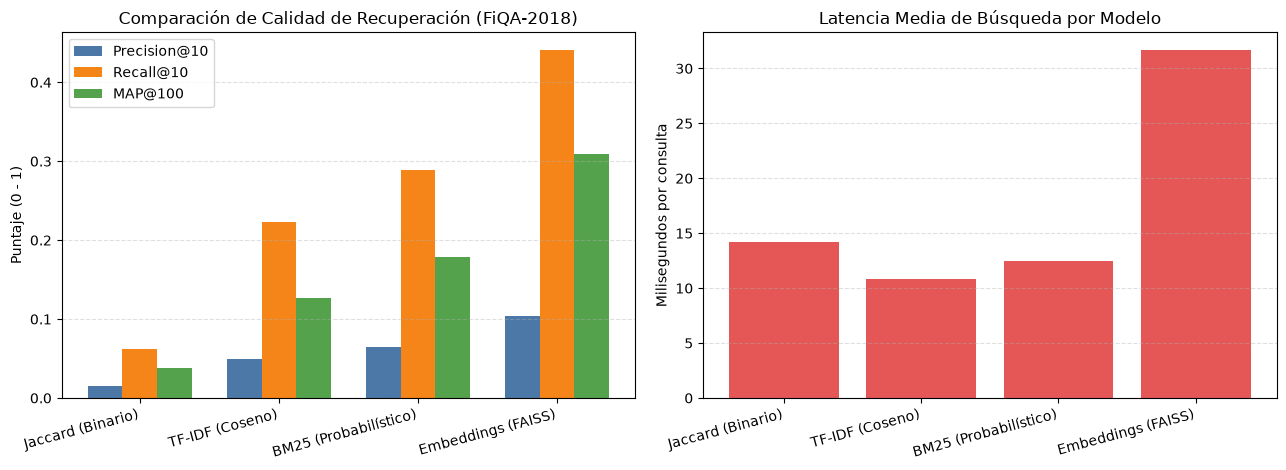


=== MUESTRA DEL DESGLOSE POR CONSULTA ===


,Modelo,Query ID,Consulta,Precision@10,Recall@10,AP@100
0,Jaccard (Binario),8,How to deposit a cheque issued to an associate...,0.1,0.5,0.100000
1,Jaccard (Binario),15,Can I send a money order from USPS as a business?,0.0,0.0,0.000000
2,Jaccard (Binario),18,1 EIN doing business under multiple business n...,0.0,0.0,0.000000
3,Jaccard (Binario),26,Applying for and receiving business credit,0.0,0.0,0.000000
4,Jaccard (Binario),34,401k Transfer After Business Closure,0.0,0.0,0.000000
5,Jaccard (Binario),42,What are the ins/outs of writing equipment pur...,0.0,0.0,0.000000
6,Jaccard (Binario),56,Can a entrepreneur hire a self-employed busine...,0.0,0.0,0.076923
7,Jaccard (Binario),68,Intentions of Deductible Amount for Small Busi...,0.0,0.0,0.000000


In [7]:
# ============================================================================
# BLOQUE 5: EVALUACIÓN OFICIAL (PRECISION@K, RECALL@K, MAP) Y GRÁFICAS
# ============================================================================

FORZAR_REEVALUACION = False  # Pon True si modificaste parámetros de modelos o MAX_DOCS


def calcular_metricas_consulta(ranking_doc_ids: list, relevantes_set: set, k: int = TOP_K_EVAL):
    """
    Calcula Precision@k, Recall@k y Average Precision (AP) sin redondeo prematuro.
    """
    if not relevantes_set:
        return 0.0, 0.0, 0.0

    top_k = ranking_doc_ids[:k]
    aciertos_k = sum(1 for doc in top_k if doc in relevantes_set)

    precision_k = aciertos_k / k if k > 0 else 0.0
    recall_k = aciertos_k / len(relevantes_set)

    suma_precisiones = 0.0
    relevantes_vistos = 0
    for idx, doc_id in enumerate(ranking_doc_ids, start=1):
        if doc_id in relevantes_set:
            relevantes_vistos += 1
            suma_precisiones += relevantes_vistos / idx

    ap = suma_precisiones / len(relevantes_set)
    return float(precision_k), float(recall_k), float(ap)


def evaluar_sistema_fiqa(
    queries_dict: dict,
    qrels_dict: dict,
    k: int = TOP_K_EVAL,
    profundidad_ap: int = PROFUNDIDAD_AP,
    max_queries: int = None,
):
    """
    Evalúa Jaccard, TF-IDF, BM25 y Embeddings (FAISS) sobre las consultas de prueba.
    """
    items_queries = list(queries_dict.items())
    if max_queries is not None:
        items_queries = items_queries[:max_queries]

    if not items_queries:
        raise ValueError("No hay consultas válidas en queries_dict para evaluar.")

    modelos = {
        "Jaccard (Binario)": lambda q: [d for d, _ in motor_clasico.buscar_jaccard(q, top_k=profundidad_ap)],
        "TF-IDF (Coseno)": lambda q: [d for d, _ in motor_clasico.buscar_tfidf_coseno(q, top_k=profundidad_ap)],
        "BM25 (Probabilístico)": lambda q: [d for d, _ in motor_clasico.buscar_bm25(q, top_k=profundidad_ap)],
        "Embeddings (FAISS)": lambda q: [d for d, _ in motor_semantico.buscar(q, top_k=profundidad_ap)],
    }

    filas_detalle = []
    resumen_global = []

    for nombre_modelo, fn_busqueda in modelos.items():
        t_inicio = time.time()
        lista_p, lista_r, lista_ap = [], [], []

        for q_id, texto_q in items_queries:
            ranking = fn_busqueda(texto_q)
            p, r, ap = calcular_metricas_consulta(ranking, qrels_dict[q_id], k=k)
            lista_p.append(p)
            lista_r.append(r)
            lista_ap.append(ap)
            filas_detalle.append({
                "Modelo": nombre_modelo,
                "Query ID": q_id,
                "Consulta": texto_q,
                f"Precision@{k}": p,
                f"Recall@{k}": r,
                f"AP@{profundidad_ap}": ap,
            })

        tiempo_total = time.time() - t_inicio
        resumen_global.append({
            "Modelo": nombre_modelo,
            "Consultas Evaluadas": len(items_queries),
            f"Mean Precision@{k}": round(float(np.mean(lista_p)), 4),
            f"Mean Recall@{k}": round(float(np.mean(lista_r)), 4),
            f"MAP@{profundidad_ap}": round(float(np.mean(lista_ap)), 4),
            "Latencia Media (ms/query)": round((tiempo_total / len(items_queries)) * 1000, 2),
        })

    return pd.DataFrame(filas_detalle), pd.DataFrame(resumen_global)


def graficar_metricas_modelos(df_resumen: pd.DataFrame, k: int = TOP_K_EVAL, profundidad_ap: int = PROFUNDIDAD_AP):
    """Genera gráficos comparativos de efectividad (P@k, R@k, MAP) y latencia."""
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

    modelos = df_resumen["Modelo"].tolist()
    x = np.arange(len(modelos))
    ancho = 0.25

    col_p = f"Mean Precision@{k}"
    col_r = f"Mean Recall@{k}"
    col_map = f"MAP@{profundidad_ap}"

    axes[0].bar(x - ancho, df_resumen[col_p], width=ancho, label=f"Precision@{k}", color="#4C78A8")
    axes[0].bar(x,         df_resumen[col_r], width=ancho, label=f"Recall@{k}", color="#F58518")
    axes[0].bar(x + ancho, df_resumen[col_map], width=ancho, label=f"MAP@{profundidad_ap}", color="#54A24B")
    axes[0].set_xticks(x)
    axes[0].set_xticklabels(modelos, rotation=15, ha="right")
    axes[0].set_ylabel("Puntaje (0 - 1)")
    axes[0].set_title(f"Comparación de Calidad de Recuperación (FiQA-2018)")
    axes[0].grid(axis="y", linestyle="--", alpha=0.4)
    axes[0].legend()

    axes[1].bar(modelos, df_resumen["Latencia Media (ms/query)"], color="#E45756")
    axes[1].set_xticks(x)
    axes[1].set_xticklabels(modelos, rotation=15, ha="right")
    axes[1].set_ylabel("Milisegundos por consulta")
    axes[1].set_title("Latencia Media de Búsqueda por Modelo")
    axes[1].grid(axis="y", linestyle="--", alpha=0.4)

    plt.tight_layout()
    return fig


if (
    not FORZAR_REEVALUACION
    and os.path.exists(RUTA_EVAL_RESUMEN)
    and os.path.exists(RUTA_EVAL_DETALLE)
    and queries_test
):
    df_resumen_map = pd.read_csv(RUTA_EVAL_RESUMEN)
    df_detalle_eval = pd.read_parquet(RUTA_EVAL_DETALLE)
    if int(df_resumen_map["Consultas Evaluadas"].iloc[0]) == len(queries_test):
        print(f"Resultados de evaluación cargados desde caché ('{RUTA_EVAL_RESUMEN}').")
    else:
        df_detalle_eval, df_resumen_map = evaluar_sistema_fiqa(queries_test, qrels_test)
        df_resumen_map.to_csv(RUTA_EVAL_RESUMEN, index=False)
        df_detalle_eval.to_parquet(RUTA_EVAL_DETALLE, index=False)
elif queries_test:
    df_detalle_eval, df_resumen_map = evaluar_sistema_fiqa(queries_test, qrels_test)
    df_resumen_map.to_csv(RUTA_EVAL_RESUMEN, index=False)
    df_detalle_eval.to_parquet(RUTA_EVAL_DETALLE, index=False)
else:
    df_detalle_eval = pd.DataFrame()
    df_resumen_map = pd.DataFrame()
    print("[AVISO] Evaluación omitida porque no hay queries_test cargadas.")

if not df_resumen_map.empty:
    print(f"=== RESUMEN GLOBAL EN FIQA-2018 ({len(queries_test):,} consultas, k={TOP_K_EVAL}) ===")
    display(df_resumen_map)
    fig_eval = graficar_metricas_modelos(df_resumen_map)
    plt.show()
    print("\n=== MUESTRA DEL DESGLOSE POR CONSULTA ===")
    display(df_detalle_eval.head(8))

## 6. Comparación de Modelos y Análisis Cualitativo/Cuantitativo
### Requerimiento (f): Comparación por tipo de consulta y casos de éxito/fallo
A partir de los resultados reales de la evaluación anterior:
1. **Análisis segmentado por tipo de consulta:** comparamos `AP@100` y `Recall@10` de los 4 modelos según:
   - **Longitud de la consulta** (consultas cortas `<= 5` tokens útiles vs medianas/largas `> 5` tokens).
   - **Presencia de términos numéricos o acrónimos en mayúsculas** (p. ej. `401k`, `IRA`, `ETF`, `IRS`, `HSA`, cifras) frente a consultas en lenguaje natural puramente conceptual.
2. **Casos reales con evidencia textual:** extraemos automáticamente los casos donde **Embeddings supera ampliamente tanto a BM25 como a TF-IDF**, y los casos donde **BM25 o TF-IDF superan ampliamente a Embeddings**, imprimiendo los rankings de los 4 modelos y el texto del documento relevante real (`qrels`) junto con el falso positivo del modelo superado.

In [8]:
# ============================================================================
# BLOQUE 6: COMPARACIÓN POR TIPO DE CONSULTA Y EXTRACCIÓN DE CASOS REALES
# ============================================================================

def clasificar_consulta(texto: str):
    tokens_limpios = preprocesar_texto(texto)
    tiene_num_o_sigla = bool(re.search(r"\b([A-Z]{2,}|\d+[a-zA-Z]*)\b", texto))
    grupo_len = "Corta (<=5 tokens)" if len(tokens_limpios) <= 5 else "Media/Larga (>5 tokens)"
    grupo_tipo = "Con siglas/números" if tiene_num_o_sigla else "Lenguaje natural puro"
    return grupo_len, grupo_tipo


def comparar_consulta_detallada(consulta: str, q_id_ref: str = None, top_n: int = 3):
    """
    Imprime tabla comparativa Top-N de los 4 modelos, marca [REL] según qrels y muestra
    el texto real del documento relevante y del mejor falso positivo para análisis cualitativo.
    """
    relevantes = qrels_test.get(q_id_ref, set()) if q_id_ref else set()

    rankings = {
        "Jaccard (Binario)": motor_clasico.buscar_jaccard(consulta, top_k=top_n),
        "TF-IDF (Coseno)": motor_clasico.buscar_tfidf_coseno(consulta, top_k=top_n),
        "BM25 (Probabilístico)": motor_clasico.buscar_bm25(consulta, top_k=top_n),
        "Embeddings (FAISS)": motor_semantico.buscar(consulta, top_k=top_n),
    }

    def fmt(lista_res):
        salida = [
            f"ID:{doc_id}{' [REL]' if doc_id in relevantes else ''} ({score})"
            for doc_id, score in lista_res
        ]
        while len(salida) < top_n:
            salida.append("-")
        return salida

    tabla = pd.DataFrame({"Posición": [f"#{i+1}" for i in range(top_n)]})
    for nombre, res in rankings.items():
        tabla[nombre] = fmt(res)

    print(f"\nConsulta [{q_id_ref}]: '{consulta}'")
    if relevantes:
        print(f"Documentos relevantes oficiales (qrels): {sorted(relevantes)}")
    display(tabla)

    if relevantes:
        doc_rel_ejemplo = sorted(relevantes)[0]
        print(f"--- Texto del documento relevante [ID:{doc_rel_ejemplo}] ---")
        print(corpus[doc_rel_ejemplo][:500] + ("..." if len(corpus[doc_rel_ejemplo]) > 500 else ""))

    for modelo_nombre in ["TF-IDF (Coseno)", "BM25 (Probabilístico)", "Embeddings (FAISS)"]:
        res_m = rankings[modelo_nombre]
        if res_m:
            top1_id, top1_sc = res_m[0]
            etiqueta = "RELEVANTE" if top1_id in relevantes else "NO RELEVANTE"
            print(f"--- Top-1 de {modelo_nombre} [ID:{top1_id} | {etiqueta} | score={top1_sc}] ---")
            print(corpus[top1_id][:350] + ("..." if len(corpus[top1_id]) > 350 else ""))


if not df_detalle_eval.empty:
    # 1. Análisis segmentado por longitud y tipo de consulta
    df_seg = df_detalle_eval.copy()
    clasif = df_seg["Consulta"].apply(clasificar_consulta)
    df_seg["Grupo Longitud"] = [c[0] for c in clasif]
    df_seg["Tipo Léxico"] = [c[1] for c in clasif]

    col_ap = f"AP@{PROFUNDIDAD_AP}"
    col_rec = f"Recall@{TOP_K_EVAL}"

    print(f"=== DESEMPEÑO PROMEDIO ({col_ap} y {col_rec}) POR LONGITUD DE CONSULTA ===")
    display(df_seg.pivot_table(index="Grupo Longitud", columns="Modelo", values=[col_ap, col_rec], aggfunc="mean").round(4))

    print(f"\n=== DESEMPEÑO PROMEDIO ({col_ap} y {col_rec}) POR PRESENCIA DE SIGLAS / NÚMEROS ===")
    display(df_seg.pivot_table(index="Tipo Léxico", columns="Modelo", values=[col_ap, col_rec], aggfunc="mean").round(4))

    # 2. Extracción automática de casos clave comparando Embeddings vs BM25 y TF-IDF
    df_pivot_ap = df_detalle_eval.pivot(index=["Query ID", "Consulta"], columns="Modelo", values=col_ap).reset_index()
    df_pivot_ap["Mejor_Lexico"] = df_pivot_ap[["BM25 (Probabilístico)", "TF-IDF (Coseno)"]].max(axis=1)
    df_pivot_ap["Ventaja_Embeddings"] = df_pivot_ap["Embeddings (FAISS)"] - df_pivot_ap["Mejor_Lexico"]

    print("\n=== CASOS DONDE EMBEDDINGS SUPERA AMPLIAMENTE A BM25 Y TF-IDF ===")
    casos_sem = df_pivot_ap.sort_values(by="Ventaja_Embeddings", ascending=False).head(2)
    for _, fila in casos_sem.iterrows():
        comparar_consulta_detallada(fila["Consulta"], q_id_ref=fila["Query ID"], top_n=3)

    print("\n=== CASOS DONDE BM25 / TF-IDF SUPERAN AMPLIAMENTE A EMBEDDINGS ===")
    casos_lex = df_pivot_ap.sort_values(by="Ventaja_Embeddings", ascending=True).head(2)
    for _, fila in casos_lex.iterrows():
        comparar_consulta_detallada(fila["Consulta"], q_id_ref=fila["Query ID"], top_n=3)
else:
    print("[AVISO] Ejecuta primero el Bloque 5 con queries/qrels para generar el análisis comparativo.")

=== DESEMPEÑO PROMEDIO (AP@100 y Recall@10) POR LONGITUD DE CONSULTA ===


AP@100                     \
Modelo                  BM25 (Probabilístico) Embeddings (FAISS)   
Grupo Longitud                                                     
Corta (<=5 tokens)                     0.1601             0.2780   
Media/Larga (>5 tokens)                0.1922             0.3312   

                                                           \
Modelo                  Jaccard (Binario) TF-IDF (Coseno)   
Grupo Longitud                                              
Corta (<=5 tokens)                 0.0298           0.116   
Media/Larga (>5 tokens)            0.0443           0.135   

                                    Recall@10                     \
Modelo                  BM25 (Probabilístico) Embeddings (FAISS)   
Grupo Longitud                                                     
Corta (<=5 tokens)                     0.2581             0.4143   
Media/Larga (>5 tokens)                0.3102             0.4599   

                                                           
Modelo                  Jaccard (Binario) TF-IDF (Coseno)  
Grupo Longitud                                             
Corta (<=5 tokens)                 0.0442          0.1964  
Media/Larga (>5 tokens)            0.0751          0.2416


=== DESEMPEÑO PROMEDIO (AP@100 y Recall@10) POR PRESENCIA DE SIGLAS / NÚMEROS ===


AP@100                     \
Modelo                BM25 (Probabilístico) Embeddings (FAISS)   
Tipo Léxico                                                      
Con siglas/números                   0.2306             0.3602   
Lenguaje natural puro                0.1600             0.2908   

                                                                    Recall@10  \
Modelo                Jaccard (Binario) TF-IDF (Coseno) BM25 (Probabilístico)   
Tipo Léxico                                                                     
Con siglas/números               0.0504          0.1830                0.3530   
Lenguaje natural puro            0.0339          0.1066                0.2653   

                                                                            
Modelo                Embeddings (FAISS) Jaccard (Binario) TF-IDF (Coseno)  
Tipo Léxico                                                                 
Con siglas/números                0.4912            0.0889          0.2872  
Lenguaje natural puro             0.4229            0.0527          0.1995


=== CASOS DONDE EMBEDDINGS SUPERA AMPLIAMENTE A BM25 Y TF-IDF ===

Consulta [603]: 'Will one’s education loan application be rejected if one doesn't have a payslip providing collateral?'
Documentos relevantes oficiales (qrels): ['456440']


,Posición,Jaccard (Binario),TF-IDF (Coseno),BM25 (Probabilístico),Embeddings (FAISS)
0,#1,ID:121731 (0.125),ID:121731 (0.1815),ID:64103 (20.5624),ID:456440 [REL] (0.592)
1,#2,ID:67320 (0.1034),ID:67320 (0.1674),ID:86952 (18.4922),ID:61014 (0.5659)
2,#3,ID:375922 (0.1),ID:368010 (0.1661),ID:121731 (18.4091),ID:567424 (0.5506)


... (3 outputs left out)

,Posición,Jaccard (Binario),TF-IDF (Coseno),BM25 (Probabilístico),Embeddings (FAISS)
0,#1,ID:69915 (0.2143),ID:69915 (0.2855),ID:462892 [REL] (31.0327),ID:286930 (0.622)
1,#2,ID:399115 (0.1875),ID:259777 (0.2649),ID:272590 (24.0235),ID:457254 (0.6181)
2,#3,ID:584796 (0.1818),ID:462892 [REL] (0.2585),ID:259777 (23.7398),ID:129027 (0.6156)


--- Texto del documento relevante [ID:462892] ---
The breakeven amount isn't at 8 years. You calculated how many years of paying $500 it would take to break even with one year of paying $4000. 8 x 10 years = 80 years. So by paying $500/year it will take you 80 years to have spent the same amount ($40000 total) as you did in 10 years. At this point it may seem obvious what the better choice is. Consider where you'll be after 10 years: In scenario #1 you've spent $5000 ($500*10) and have to continue spending $500/year indefinitely. In scenario #2...
--- Top-1 de TF-IDF (Coseno) [ID:69915 | NO RELEVANTE | score=0.2855] ---
The 10 year comparison between your fund and the S&P 500 -   I'd say more, but not sure it's needed.
--- Top-1 de BM25 (Probabilístico) [ID:462892 | RELEVANTE | score=31.0327] ---
The breakeven amount isn't at 8 years. You calculated how many years of paying $500 it would take to break even with one year of paying $4000. 8 x 10 years = 80 years. So by paying $500/year i

,Posición,Jaccard (Binario),TF-IDF (Coseno),BM25 (Probabilístico),Embeddings (FAISS)
0,#1,ID:403025 [REL] (0.15),ID:403025 [REL] (0.3865),ID:151037 (38.2954),ID:571124 (0.6874)
1,#2,ID:292762 (0.15),ID:292762 (0.3761),ID:436530 (34.6265),ID:187761 (0.6832)
2,#3,ID:187761 (0.1364),ID:151037 (0.352),ID:132111 (32.7772),ID:140267 (0.6487)


--- Texto del documento relevante [ID:403025] ---
Disallowed losses are created when you buy a stock */- 30 days of a sale at a loss.  When you sell and have no shares left, the loss is taken. You can't have no shares and leftover disallowed loss.
--- Top-1 de TF-IDF (Coseno) [ID:403025 | RELEVANTE | score=0.3865] ---
Disallowed losses are created when you buy a stock */- 30 days of a sale at a loss.  When you sell and have no shares left, the loss is taken. You can't have no shares and leftover disallowed loss.
--- Top-1 de BM25 (Probabilístico) [ID:151037 | NO RELEVANTE | score=38.2954] ---
Disallowed losses due to the wash sale rule are added to the basis of the repurchased shares.  In your example, on day two you paid $0.70 per share. Then the disallowed $0.30 loss from the previous day gets added to the basis, making your total basis $1.00 per share. When you sell at the end of the day for $1.00 per share, your net gain/loss is zer...
--- Top-1 de Embeddings (FAISS) [ID:571124 | N

### Guía de Interpretación de Resultados para el Informe Técnico
Una vez ejecutado el notebook completo, apoya tu análisis del informe (máx. 5 páginas) en los resultados impresos arriba considerando estos 4 ejes:
1. **Jaccard (Binario):** Al ignorar frecuencias (*TF*) e importancia inversa de términos (*IDF*), trata igual una palabra común que un término financiero específico y penaliza documentos extensos en el denominador $|Q \cup D|$.
2. **TF-IDF (Coseno):** Introduce ponderación sublineal de *TF*, discriminación por *IDF* y normalización euclidiana de longitud, reduciendo la penalización a documentos largos pero manteniendo dependencia de coincidencia léxica exacta.
3. **Okapi BM25:** La saturación no lineal de *TF* ($k_1 = 1.5$) y la normalización respecto al promedio `avgdl` ($b = 0.75$) suelen darle ventaja sobre TF-IDF y destacan particularmente cuando la consulta incluye siglas, formularios o códigos numéricos exactos (ej. `401k`, `1040`, `IRS`).
4. **Embeddings Densos (`all-MiniLM-L6-v2` + FAISS):** Captura similitud semántica ante sinónimos, paráfrasis y preguntas coloquiales (*brecha léxica*), aunque el truncamiento a 256 *subwords* y la compresión en 384 dimensiones pueden hacerle perder precisión en coincidencias exactas de códigos poco frecuentes.

## 7. Interfaz Web Interactiva (Gradio)
### Requerimiento (d): Interfaz básica
Incluye todas las funcionalidades exigidas en el PDF en una única aplicación Gradio:
1. Ejecutar consultas de texto libre (más ejemplos clicables extraídos del conjunto de prueba).
2. Elegir el modelo (**Binario Jaccard**, **Vectorial TF-IDF**, **Probabilístico BM25**, **Vectorial Semántico Embeddings + FAISS**).
3. Visualizar el **Top-N** con puntaje, indicador `[REL]` (si coincide con una consulta de `queries_test`) y el **texto completo** del documento.
4. Comparar lado a lado los resultados de los **4 modelos** con snippet legible de cada documento.
5. Visualizar las **métricas globales** (`Precision@10`, `Recall@10`, `MAP@100`), su gráfico comparativo y el desglose por consulta (leyendo de memoria o de la caché guardada en disco).

In [10]:
pip install gradio

   ---------------------------------------- 0.0/31.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/31.4 MB ? eta -:--:--
    --------------------------------------- 0.5/31.4 MB 2.3 MB/s eta 0:00:14
   -- ------------------------------------- 1.8/31.4 MB 5.5 MB/s eta 0:00:06
   --------- ------------------------------ 7.1/31.4 MB 12.4 MB/s eta 0:00:02
   -------------------- ------------------- 15.7/31.4 MB 22.5 MB/s eta 0:00:01
   -------------------- ------------------- 15.7/31.4 MB 22.5 MB/s eta 0:00:01
   -------------------- ------------------- 15.7/31.4 MB 22.5 MB/s eta 0:00:01
   -------------------- ------------------- 15.7/31.4 MB 22.5 MB/s eta 0:00:01
   -------------------- ------------------- 15.7/31.4 MB 22.5 MB/s eta 0:00:01
   -------------------- ------------------- 15.7/31.4 MB 22.5 MB/s eta 0:00:01
   -------------------- ------------------- 16.0/31.4 MB 8.3 MB/s eta 0:00:02
   -------------------- ------------------- 16.3/31.4 MB 7.5 MB/s eta 0:00:0


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [12]:
# ============================================================================
# BLOQUE 7: INTERFAZ WEB CON GRADIO (INTEGRADA EN EL MISMO NOTEBOOK)
# ============================================================================
try:
    import gradio as gr
except ImportError:
    gr = None
    print("[AVISO] `gradio` no está instalado en este entorno. Ejecuta `pip install gradio` para habilitar la interfaz web.")


def _cargar_metricas_seguro():
    res = globals().get("df_resumen_map", pd.DataFrame())
    det = globals().get("df_detalle_eval", pd.DataFrame())
    if res.empty and os.path.exists(RUTA_EVAL_RESUMEN):
        res = pd.read_csv(RUTA_EVAL_RESUMEN)
    if det.empty and os.path.exists(RUTA_EVAL_DETALLE):
        det = pd.read_parquet(RUTA_EVAL_DETALLE)
    return res, det


def _buscar_qrels_por_texto(consulta: str):
    consulta_norm = consulta.strip().lower()
    for q_id, q_txt in queries_test.items():
        if q_txt.strip().lower() == consulta_norm:
            return q_id, qrels_test.get(q_id, set())
    return None, set()


def ejecutar_busqueda_web(consulta: str, modelo_elegido: str, top_n: int):
    cols_ind = ["Rank", "Doc ID (FiQA)", "Relevante (qrels)", "Score", "Contenido Completo del Documento"]
    if not consulta or not consulta.strip():
        return pd.DataFrame(columns=cols_ind), pd.DataFrame(), "Ingresa una consulta para buscar."

    top_n = int(top_n)
    q_id_match, relevantes = _buscar_qrels_por_texto(consulta)

    if modelo_elegido == "Binario (Jaccard)":
        res_sel = motor_clasico.buscar_jaccard(consulta, top_k=top_n)
    elif modelo_elegido == "Vectorial (TF-IDF + Coseno)":
        res_sel = motor_clasico.buscar_tfidf_coseno(consulta, top_k=top_n)
    elif modelo_elegido == "Probabilístico (BM25)":
        res_sel = motor_clasico.buscar_bm25(consulta, top_k=top_n)
    else:
        res_sel = motor_semantico.buscar(consulta, top_k=top_n)

    filas_ind = [
        {
            "Rank": i + 1,
            "Doc ID (FiQA)": doc_id,
            "Relevante (qrels)": "SÍ [REL]" if doc_id in relevantes else ("No" if relevantes else "-"),
            "Score": score,
            "Contenido Completo del Documento": corpus.get(doc_id, ""),
        }
        for i, (doc_id, score) in enumerate(res_sel)
    ]
    df_individual = pd.DataFrame(filas_ind, columns=cols_ind)

    def fmt_celdas(lista):
        salida = []
        for d, s in lista:
            marca = " [REL]" if d in relevantes else ""
            snippet = corpus.get(d, "")[:95].replace("\n", " ")
            salida.append(f"ID:{d}{marca} ({s}) — {snippet}...")
        while len(salida) < top_n:
            salida.append("-")
        return salida

    df_comp = pd.DataFrame({
        "Rank": [i + 1 for i in range(top_n)],
        "Jaccard (Binario)": fmt_celdas(motor_clasico.buscar_jaccard(consulta, top_k=top_n)),
        "TF-IDF (Coseno)": fmt_celdas(motor_clasico.buscar_tfidf_coseno(consulta, top_k=top_n)),
        "BM25 (Probabilístico)": fmt_celdas(motor_clasico.buscar_bm25(consulta, top_k=top_n)),
        "Embeddings (FAISS)": fmt_celdas(motor_semantico.buscar(consulta, top_k=top_n)),
    })

    if q_id_match:
        estado = f"Consulta detectada en Test Set (`query_id={q_id_match}`, {len(relevantes)} relevantes en qrels)."
    else:
        estado = f"Consulta libre ejecutada sobre {len(corpus):,} documentos."

    return df_individual, df_comp, estado


if gr is not None:
    df_resumen_ui, df_detalle_ui = _cargar_metricas_seguro()
    n_eval_ui = int(df_resumen_ui["Consultas Evaluadas"].iloc[0]) if not df_resumen_ui.empty else 0

    ejemplos_ui = [
        ["Should I invest in a Roth IRA or traditional 401k for retirement?"],
        ["How can I improve my credit score quickly without paying fees?"],
        ["What is the difference between an index fund and an ETF?"],
    ]
    if queries_test:
        primeras_test = list(queries_test.values())[:3]
        ejemplos_ui = [[q] for q in primeras_test] + ejemplos_ui[:1]

    with gr.Blocks(title="SRI FiQA-2018 — Proyecto 1er Bimestre") as demo:
        gr.Markdown("# Sistema de Recuperación de Información — Corpus FiQA-2018 (BeIR)")
        gr.Markdown(
            f"Comparación de modelos clásicos (Jaccard, TF-IDF, BM25) y recuperación semántica "
            f"(`{MODELO_EMBEDDINGS}` + FAISS) sobre **{len(corpus):,}** documentos financieros."
        )

        with gr.Tab("1. Búsqueda y Comparación de Modelos"):
            with gr.Row():
                txt_consulta = gr.Textbox(
                    label="Consulta financiera en texto libre",
                    placeholder="Ej: Should I invest in a Roth IRA or traditional 401k for retirement?",
                    scale=3,
                )
                dd_modelo = gr.Dropdown(
                    choices=[
                        "Binario (Jaccard)",
                        "Vectorial (TF-IDF + Coseno)",
                        "Probabilístico (BM25)",
                        "Vectorial Semántico (Embeddings + FAISS)",
                    ],
                    value="Vectorial Semántico (Embeddings + FAISS)",
                    label="Modelo Principal",
                    scale=2,
                )
                sld_topn = gr.Slider(minimum=1, maximum=15, value=5, step=1, label="Top-N", scale=1)

            btn_buscar = gr.Button("Ejecutar Búsqueda", variant="primary")
            lbl_estado = gr.Markdown("")

            gr.Examples(examples=ejemplos_ui, inputs=[txt_consulta], label="Ejemplos rápidos (clic para probar)")

            gr.Markdown("### Ranking del Modelo Seleccionado")
            out_individual = gr.Dataframe(interactive=False, wrap=True)

            gr.Markdown("### Comparación Lado a Lado entre los 4 Modelos")
            out_comparacion = gr.Dataframe(interactive=False, wrap=True)

            btn_buscar.click(
                fn=ejecutar_busqueda_web,
                inputs=[txt_consulta, dd_modelo, sld_topn],
                outputs=[out_individual, out_comparacion, lbl_estado],
            )

        with gr.Tab("2. Evaluación Oficial (Precision, Recall, MAP)"):
            if not df_resumen_ui.empty:
                gr.Markdown(f"### Resumen Global de Métricas en FiQA-2018 ({n_eval_ui:,} consultas evaluadas)")
                gr.Dataframe(value=df_resumen_ui, interactive=False)
                gr.Plot(value=graficar_metricas_modelos(df_resumen_ui), label="Gráfico Comparativo")
                gr.Markdown("### Desglose por Consulta (Muestra de 100 filas)")
                gr.Dataframe(value=df_detalle_ui.head(100), interactive=False)
            else:
                gr.Markdown(
                    "**Aún no hay métricas calculadas.** Ejecuta el Bloque 5 (evaluación sobre `queries_test`) "
                    "para poblar esta pestaña."
                )

    # Para iniciar la interfaz desde el notebook o generar un enlace público temporal (Colab),
    # descomenta la siguiente línea:
    demo.launch(share=True)
    print("Interfaz web Gradio configurada correctamente. Descomenta 'demo.launch(share=True)' para lanzarla.")

* Running on local URL:  http://127.0.0.1:7860
* Running on public URL: https://67b22f5051b620aa54.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Interfaz web Gradio configurada correctamente. Descomenta 'demo.launch(share=True)' para lanzarla.
